# Практические занятия Листок 4. Классическое, статистическое, геометрическое определение вероятности


In [60]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, factorial
from scipy import integrate
import sympy as sp
from fractions import Fraction
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

### **4.1** Корзина содержит 23 шара: 8 белых, 6 синих и 9 красных. Извлекаются 6 шаров (без возвращения).
Найдите вероятности: a) A = {все шары красные}; б) B = {3 синих, 2 белых и 1 красный}; в) D = {в точности 4 белых шара}; г) случай с возвращением.


In [61]:
N_total = comb(23, 6)
P_a = comb(9, 6) / N_total
P_b = comb(6, 3) * comb(8, 2) * comb(9, 1) / N_total
P_c = comb(8, 4) * comb(15, 2) / N_total
P_d = (9 / 23) ** 6

print(f'a) P(A) = {Fraction(comb(9,6), N_total)} = {P_a:.10f}')
print(f'б) P(B) = {P_b:.10f}')
print(f'в) P(D) = {P_c:.10f}')
print(f'г) P(A) с возвращением = {P_d:.10f}')


a) P(A) = 4/4807 = 0.0008321198
б) P(B) = 0.0499271895
в) P(D) = 0.0728104847
г) P(A) с возвращением = 0.0035899470


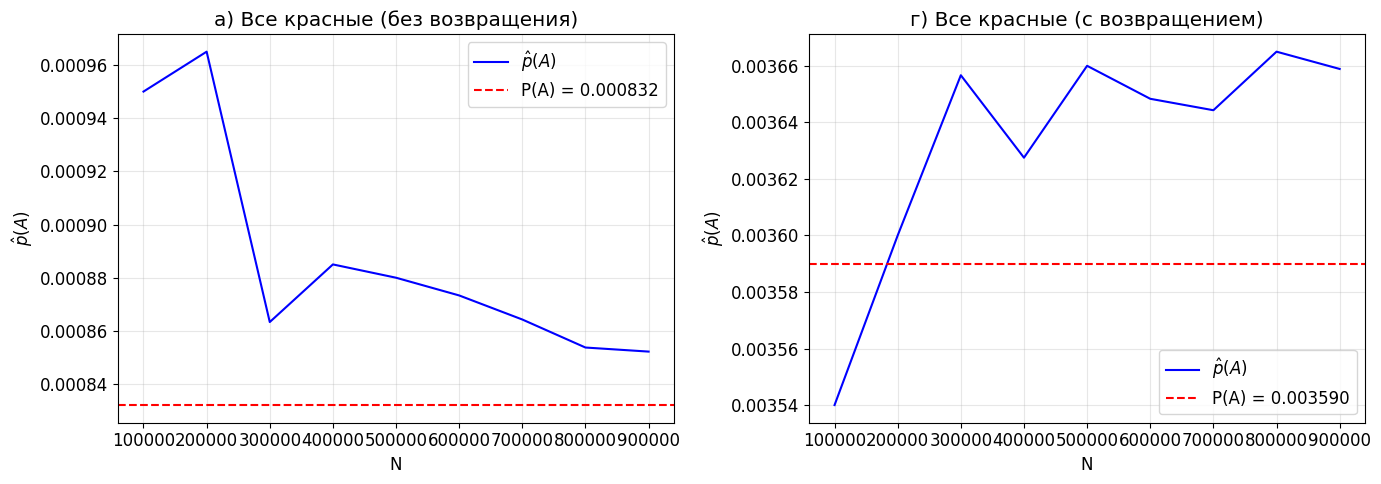

Оценка P(A) без возвращения: 0.000852  (точное -> 0.000832)
Оценка P(A) с возвращением:   0.003659  (точное -> 0.003590)


In [62]:
# Статистическое моделирование для a) и г)
N_sim = 900000
batch = 100000
n_batches = N_sim // batch

cum_a, cum_d, Ns = [], [], []
cnt_a, cnt_d = 0, 0

for i in range(n_batches):
    # Без возвращения (случайная перестановка 23 шаров, берём первые 6)
    rand = np.random.rand(batch, 23)
    perm = np.argsort(rand, axis=1)
    draws = perm[:, :6]
    all_red_wr = np.all(draws >= 14, axis=1)  # красные шары
    cnt_a += np.sum(all_red_wr)

    # С возвращением
    draws_r = np.random.randint(0, 23, size=(batch, 6))
    all_red_r = np.all(draws_r >= 14, axis=1)
    cnt_d += np.sum(all_red_r)

    total = (i + 1) * batch
    cum_a.append(cnt_a / total)
    cum_d.append(cnt_d / total)
    Ns.append(total)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(Ns, cum_a, 'b-', lw=1.5, label=r'$\hat{p}(A)$')
axes[0].axhline(y=P_a, color='r', ls='--', label=f'P(A) = {P_a:.6f}')
axes[0].set_xlabel('N'); axes[0].set_ylabel(r'$\hat{p}(A)$')
axes[0].set_title('a) Все красные (без возвращения)')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(Ns, cum_d, 'b-', lw=1.5, label=r'$\hat{p}(A)$')
axes[1].axhline(y=P_d, color='r', ls='--', label=f'P(A) = {P_d:.6f}')
axes[1].set_xlabel('N'); axes[1].set_ylabel(r'$\hat{p}(A)$')
axes[1].set_title('г) Все красные (с возвращением)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f'Оценка P(A) без возвращения: {cum_a[-1]:.6f}  (точное -> {P_a:.6f})')
print(f'Оценка P(A) с возвращением:   {cum_d[-1]:.6f}  (точное -> {P_d:.6f})')


### **4.2** 5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест.
A — любые две женщины не сидят рядом; B — все мужчины сидят рядом.


In [63]:
# A: Сначала сажаем 5 мужчин (5! способов), образуя 6 «промежутков».
#    Затем 5 женщин размещаем в 6 промежутков: A(6,5)=6!
P_A = factorial(5) * factorial(6) / factorial(10)

# B: Все мужчины - единый блок. 6 единиц (5 женщин + блок): 6! способов -> внутри блока 5!
P_B = factorial(6) * factorial(5) / factorial(10)

print(f'P(A) = {P_A:.6f} = {Fraction(int(factorial(5)*factorial(6)), factorial(10))}')
print(f'P(B) = {P_B:.6f} = {Fraction(int(factorial(6)*factorial(5)), factorial(10))}')

# Моделирование
N = 300000
cnt_A = cnt_B = 0
for _ in range(N):
    perm = np.random.permutation(10)
    women = sorted(perm[:5])
    gaps = [women[i+1] - women[i] for i in range(4)]
    if all(g > 1 for g in gaps):
        cnt_A += 1
    men = sorted(perm[5:])
    if men[-1] - men[0] == 4:
        cnt_B += 1
print(f'Моделирование: P(A) = {cnt_A/N:.6f}, P(B) = {cnt_B/N:.6f}')


P(A) = 0.023810 = 1/42
P(B) = 0.023810 = 1/42
Моделирование: P(A) = 0.023647, P(B) = 0.023573


### **4.3** Симметричную монету бросают до первого появления герба. Найдите вероятность события A = {произведено не более пяти бросаний}.


In [64]:
# P(A) = 1/2 + 1/4 + 1/8 + 1/16 + 1/32 = 31/32
P = sum(sp.Rational(1, 2**k) for k in range(1, 6))
print(f'P(A) = {float(P):.6f}')

# Моделирование
N = 500000
tosses = np.random.geometric(0.5, size=N)  # число бросков до первого успеха
print(f'Моделирование: P(A) = {np.mean(tosses <= 5):.6f}')


P(A) = 0.968750
Моделирование: P(A) = 0.968868


### **4.4** Симметричную монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд. Найти вероятность того, что потребуется чётное число бросаний.


In [65]:
p = sp.Rational(2, 3)
print(f'P(чётное) = {float(p):.6f}')

# Моделирование
N = 300000
cnt = 0
for _ in range(N):
    prev = np.random.random() < 0.5
    t = 1
    while True:
        t += 1
        cur = np.random.random() < 0.5
        if cur == prev:
            break
        prev = cur
    if t % 2 == 0:
        cnt += 1
print(f'Моделирование: P(чётное) = {cnt/N:.6f}')


P(чётное) = 0.666667
Моделирование: P(чётное) = 0.667587


### **4.5** Несимметричная монета (P(герб) = $p$ = 0,7) бросается до двух одинаковых сторон подряд. Найти вероятность того, что потребуется: а) чётное число бросаний; б) число бросаний, кратное 4.


In [66]:
# a = P(герб) = 0.7, b = P(решка) = 0.3
a, b = sp.Rational(7, 10), sp.Rational(3, 10)
P_even = (a**2 + b**2) / (1 - a*b)
P_div4 = a*b*(a**2 + b**2) / (1 - a**2 * b**2)
print(f'а) P(чётное) =  {float(P_even):.6f}')
print(f'б) P(кратно 4) = {float(P_div4):.6f}')

# Моделирование
N = 300000
p_val = 0.7
cnt_e = cnt_4 = 0
for _ in range(N):
    prev = np.random.random() < p_val
    t = 1
    while True:
        t += 1
        cur = np.random.random() < p_val
        if cur == prev:
            break
        prev = cur
    if t % 2 == 0:
        cnt_e += 1
    if t % 4 == 0:
        cnt_4 += 1
print(f'Моделирование: P(чётное) = {cnt_e/N:.6f}')
print(f'Моделирование: P(кратно 4) = {cnt_4/N:.6f}')


а) P(чётное) =  0.734177
б) P(кратно 4) = 0.127419
Моделирование: P(чётное) = 0.733953
Моделирование: P(кратно 4) = 0.127363


### **4.6** Два лица A и B условились встретиться между 2 и 3 часами дня. A ждёт 10 минут, B ждёт 12 минут. Найти вероятность встречи. Построить график относительной частоты от N = 150000.


P(A) = 0.332778


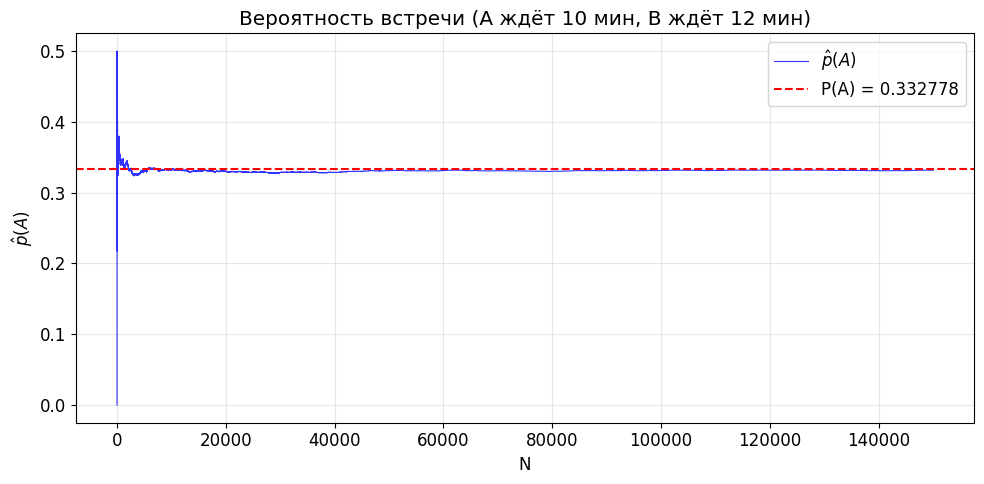

Оценка p_hat(A) = 0.331647


In [67]:
def len_x(y):
    return min(60, y + 10) - max(0, y - 12)
area, _ = integrate.quad(len_x, 0, 60)
P_exact = area / 3600
print(f'P(A) = {P_exact:.6f}')

# Моделирование
N = 150000
x = np.random.uniform(0, 60, N)
y = np.random.uniform(0, 60, N)
meet = (x - y >= -12) & (x - y <= 10)
cum = np.cumsum(meet) / np.arange(1, N + 1)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N+1), cum, 'b-', lw=0.8, alpha=0.8, label=r'$\hat{p}(A)$')
plt.axhline(y=P_exact, color='r', ls='--', label=f'P(A) = {P_exact:.6f}')
plt.xlabel('N'); plt.ylabel(r'$\hat{p}(A)$')
plt.title('Вероятность встречи (A ждёт 10 мин, B ждёт 12 мин)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Оценка p_hat(A) = {np.mean(meet):.6f}')


### **4.7** Иван и Пётр договорились о встрече между 11 и 12 часами. Каждый ждёт не более 15 минут. Найти вероятности событий A–F и построить график для A (N = 150000).


P(A) = 0.437500 = 7/16 = 0.4375
P(B) = 0.562500 = 9/16 = 0.5625
P(C) = 0.500000
P(D) = 0.187500 = 3/16 = 0.1875
P(E) = 0.281250 = 9/32 = 0.28125
P(F) = 0.041667 = 1/24 = 0.041667

Моделирование (N=150000):
P_hat(A) = 0.436860
P_hat(B) = 0.563140
P_hat(C) = 0.501467
P_hat(D) = 0.186347
P_hat(E) = 0.283940
P_hat(F) = 0.041887


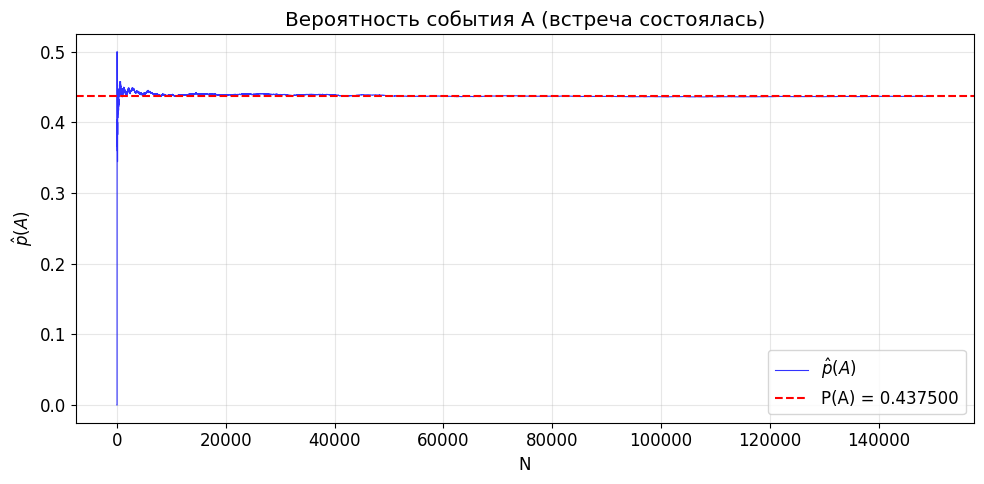

In [68]:
P_A = 1 - (45/60)**2
P_B = 1 - P_A
P_C = sp.Rational(1, 2)       # Пётр пришёл не позже Ивана (y ≤ x)
P_D = (30**2 - 2*0.5*15**2) / 3600   # оба после 11:30 и встреча
P_E = 0.5 * 45**2 / 3600      # Иван опоздал (x > y + 15)
# F: встреча и max(x,y) ≥ 55  ->  площадь = 1575 − 1425 = 150
P_F = 150 / 3600

print(f'P(A) = {P_A:.6f} = 7/16 = {7/16}')
print(f'P(B) = {P_B:.6f} = 9/16 = {9/16}')
print(f'P(C) = {float(P_C):.6f}')
print(f'P(D) = {P_D:.6f} = 3/16 = {3/16}')
print(f'P(E) = {P_E:.6f} = 9/32 = {9/32}')
print(f'P(F) = {P_F:.6f} = 1/24 = {1/24:.6f}')

# Моделирование
N = 150000
x = np.random.uniform(0, 60, N)
y = np.random.uniform(0, 60, N)
meet = np.abs(x - y) <= 15
A = meet
B = ~meet
C = y <= x
D = meet & (x > 30) & (y > 30)
E = x > y + 15
F = meet & (np.maximum(x, y) >= 55)
print(f'\nМоделирование (N={N}):')
print(f'P_hat(A) = {np.mean(A):.6f}')
print(f'P_hat(B) = {np.mean(B):.6f}')
print(f'P_hat(C) = {np.mean(C):.6f}')
print(f'P_hat(D) = {np.mean(D):.6f}')
print(f'P_hat(E) = {np.mean(E):.6f}')
print(f'P_hat(F) = {np.mean(F):.6f}')

cum = np.cumsum(A) / np.arange(1, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N+1), cum, 'b-', lw=0.8, alpha=0.8, label=r'$\hat{p}(A)$')
plt.axhline(y=float(P_A), color='r', ls='--', label=f'P(A) = {P_A:.6f}')
plt.xlabel('N'); plt.ylabel(r'$\hat{p}(A)$')
plt.title('Вероятность события A (встреча состоялась)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### **4.8** На отрезке [a, b] наудачу выбирается точка x, затем на [a, x] наудачу — точка y.
События: A — вторая точка ближе к b, чем первая к a; B — |x − y| < (b−a)/2; C — первая точка ближе ко второй, чем к b.


In [69]:
x, y = sp.symbols('x y', positive=True)

P_A = sp.integrate(1/x, (y, 1-x, x), (x, sp.Rational(1,2), 1))
P_B = sp.integrate(1/x, (y, 0, x), (x, 0, sp.Rational(1,2))) + \
      sp.integrate(1/x, (y, x - sp.Rational(1,2), x), (x, sp.Rational(1,2), 1))
P_C = sp.integrate(1/x, (y, 0, x), (x, 0, sp.Rational(1,2))) + \
      sp.integrate(1/x, (y, 2*x - 1, x), (x, sp.Rational(1,2), 1))

print(f'P(A) = {P_A} = {float(P_A):.6f}')
print(f'P(B) = {P_B} = {float(P_B):.6f}')
print(f'P(C) = {P_C} = {float(P_C):.6f}')

# Моделирование
N = 150000
xv = np.random.uniform(0, 1, N)
yv = np.random.uniform(0, xv)
A = (1 - yv) < xv
B = (xv - yv) < 0.5
C = (xv - yv) < (1 - xv)
print(f'\nМоделирование: P_hat(A) = {np.mean(A):.6f}, P_hat(B) = {np.mean(B):.6f}, P_hat(C) = {np.mean(C):.6f}')


P(A) = 1 - log(2) = 0.306853
P(B) = log(2)/2 + 1/2 = 0.846574
P(C) = log(2) = 0.693147

Моделирование: P_hat(A) = 0.307420, P_hat(B) = 0.847393, P_hat(C) = 0.692380


### **4.9** Отрезок [0, 1] случайно делится на 3 части. Найти вероятность того, что из частей можно составить остроугольный треугольник.


P(A) = 3*ln(2) − 2 = 0.0794415417


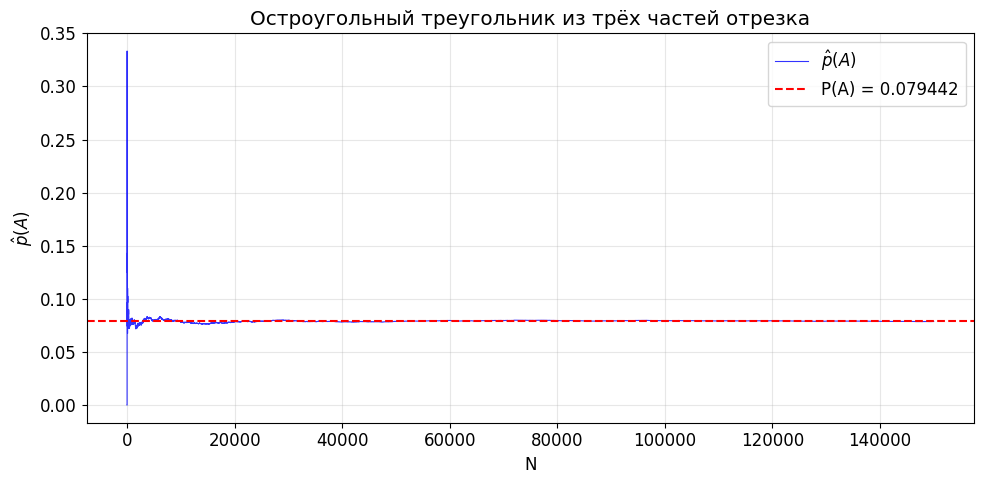

Оценка p_hat(A) = 0.078667


In [70]:
P_exact = 3 * sp.ln(2) - 2
print(f'P(A) = 3*ln(2) − 2 = {float(P_exact):.10f}')

# Моделирование
N = 150000
u = np.random.uniform(0, 1, N)
v = np.random.uniform(0, 1, N)
x = np.minimum(u, v)
y = np.maximum(u, v)
a, b, c = x, y - x, 1 - y
is_triangle = (a < 0.5) & (b < 0.5) & (c < 0.5)
is_acute = (a**2 + b**2 > c**2) & (a**2 + c**2 > b**2) & (b**2 + c**2 > a**2)
A = is_triangle & is_acute
cum = np.cumsum(A) / np.arange(1, N + 1)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, N+1), cum, 'b-', lw=0.8, alpha=0.8, label=r'$\hat{p}(A)$')
plt.axhline(y=float(P_exact), color='r', ls='--', label=f'P(A) = {float(P_exact):.6f}')
plt.xlabel('N'); plt.ylabel(r'$\hat{p}(A)$')
plt.title('Остроугольный треугольник из трёх частей отрезка')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Оценка p_hat(A) = {np.mean(A):.6f}')


### **4.10** В круге радиуса 1 наудачу выбирается отрезок (две случайные точки круга). Найти вероятность того, что длина отрезка будет меньше радиуса.


In [71]:
P_exact = 1 - 3*sp.sqrt(3) / (4*sp.pi)
print(f'P(A) = {float(P_exact):.10f}')

# Моделирование
N = 300000
r1 = np.sqrt(np.random.uniform(0, 1, N))
t1 = np.random.uniform(0, 2*np.pi, N)
r2 = np.sqrt(np.random.uniform(0, 1, N))
t2 = np.random.uniform(0, 2*np.pi, N)
x1, y1 = r1*np.cos(t1), r1*np.sin(t1)
x2, y2 = r2*np.cos(t2), r2*np.sin(t2)
dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
print(f'Моделирование: P_hat(A) = {np.mean(dist < 1):.6f}')


P(A) = 0.5865033284
Моделирование: P_hat(A) = 0.588487


### **4.11** n лиц условились о встрече между 10 и 11, ждут 60·q минут (q < 1). Доказать $P_n = n·q^(n−1) − (n−1)·q^n$. Проверить для n = 2 и n = 3. Для n = 3 найти вероятность, что встреча по крайней мере двух лиц состоится.


In [72]:
# P_n — вероятность того, что все n человек встретятся (размах ≤ q)
q = sp.Symbol('q', positive=True)

def P_all(n_val, q_val):
    return n_val * q_val**(n_val-1) - (n_val-1) * q_val**n_val

print('Формула P_n = n*q^(n−1) − (n−1)*q^n')
print(f'  n=2: P = {sp.expand(P_all(2, q))}')
print(f'  n=3: P = {sp.expand(P_all(3, q))}')

# Проверка моделированием
for n_val in [2, 3]:
    for q_val in [0.3, 0.5]:
        N = 200000
        arr = np.random.uniform(0, 1, (N, n_val))
        rng = np.max(arr, axis=1) - np.min(arr, axis=1)
        p_sim = np.mean(rng <= q_val)
        p_ex = float(P_all(n_val, q_val))
        print(f'  n={n_val}, q={q_val}: симуляция={p_sim:.4f}, точно={p_ex:.4f}')

# Для n=3: P(встреча >= 2 лиц) или 1 − P(никакие двое не встретились)
q_val = 0.3
P_at_least_2 = 1 - (1 - 2*q_val)**3
print(f'\nn=3, q={q_val}: P(встреча ≥ 2) = 1−(1−2q)**3 = {P_at_least_2:.6f}')

N = 200000
arr = np.random.uniform(0, 1, (N, 3))
d12 = np.abs(arr[:,0] - arr[:,1]) <= q_val
d13 = np.abs(arr[:,0] - arr[:,2]) <= q_val
d23 = np.abs(arr[:,1] - arr[:,2]) <= q_val
at_least_2 = d12 | d13 | d23
print(f'Моделирование: P_hat(встреча ≥ 2) = {np.mean(at_least_2):.6f}')


Формула P_n = n*q^(n−1) − (n−1)*q^n
  n=2: P = -q**2 + 2*q
  n=3: P = -2*q**3 + 3*q**2
  n=2, q=0.3: симуляция=0.5103, точно=0.5100
  n=2, q=0.5: симуляция=0.7502, точно=0.7500
  n=3, q=0.3: симуляция=0.2158, точно=0.2160
  n=3, q=0.5: симуляция=0.5000, точно=0.5000

n=3, q=0.3: P(встреча ≥ 2) = 1−(1−2q)**3 = 0.936000
Моделирование: P_hat(встреча ≥ 2) = 0.935625


### **4.12** (Продолжение) n лиц с разными временами ожидания $w_1$, …, $w_n$.
a) n = 2: $P_2$ = 1 − (1−w₁)²/2 − (1−w₂)²/2;  b) n = 3 (формула);  c) n = 3, w = (1/4, 1/3, 1/2);  d) n = 4.


In [73]:
w1, w2, w3, w4 = sp.symbols('w1 w2 w3 w4', positive=True)

# a) n = 2
P2 = 1 - (1-w1)**2/2 - (1-w2)**2/2
print(f'a) P_2 = {sp.expand(P2)}')

# b) n = 3
P3 = (w1*w2 + w1*w3 + w2*w3
      - sp.Rational(1,2)*(w1*w2**2 + w1*w3**2 + w2*w3**2)
      - sp.Rational(1,3)*w1**3 - sp.Rational(1,6)*w2**3)
print(f'b) P_3 = {sp.expand(P3)}')

# c) w1=1/4, w2=1/3, w3=1/2
P3c = P3.subs([(w1, sp.Rational(1,4)), (w2, sp.Rational(1,3)), (w3, sp.Rational(1,2))])
print(f'c) P_3 = {P3c} = {float(P3c):.6f}')

# d) n = 4
P4 = (w1*w2*w3 + w1*w2*w4 + w1*w3*w4 + w2*w3*w4
      - w4**2/2*(w1*w2 + w1*w3 + w2*w3)
      - w3**3/6*(w1 + w2)
      - w1*w2*w3**2/2 - w1*w3**3/2 - w1**4/4 - w2**4/12)
print(f'd) P_4 задан формулой')

# Проверка c) моделированием
# Встреча всех n пересечение интервалов
N = 300000
w = np.array([1/4, 1/3, 1/2])
arr = np.random.uniform(0, 1, (N, 3))
meet_all = np.max(arr, axis=1) <= np.min(arr + w, axis=1)
print(f'\nМоделирование c): P_hat_3 = {np.mean(meet_all):.6f}  (точно -> {float(P3c):.6f})')

# Проверка a) для конкретных w1, w2
w_test = [0.3, 0.4]
arr2 = np.random.uniform(0, 1, (N, 2))
meet2 = np.max(arr2, axis=1) <= np.min(arr2 + np.array(w_test), axis=1)
P2_ex = float(P2.subs([(w1, 0.3), (w2, 0.4)]))
print(f'Моделирование a) w=(0.3,0.4): P_hat_2 = {np.mean(meet2):.6f}  (точно -> {P2_ex:.6f})')


a) P_2 = -w1**2/2 + w1 - w2**2/2 + w2
b) P_3 = -w1**3/3 - w1*w2**2/2 + w1*w2 - w1*w3**2/2 + w1*w3 - w2**3/6 - w2*w3**2/2 + w2*w3
c) P_3 = 1435/5184 = 0.276813
d) P_4 задан формулой

Моделирование c): P_hat_3 = 0.276577  (точно -> 0.276813)
Моделирование a) w=(0.3,0.4): P_hat_2 = 0.574007  (точно -> 0.575000)


### **4.13** В корзину с n шарами опускают белый шар. Найти вероятность извлечь белый шар, если число белых шаров имеет биномиальное распределение $Bin(n, p)$. Решить для общего случая и для n = 10, p = 1/3.


In [74]:
# W ~ Bin(n, p) — начальное число белых. После добавления: n+1 шаров, W+1 белых.
n, p = sp.symbols('n p', positive=True)
P_gen = (n*p + 1) / (n + 1)
print(f'Общий случай: P(белый) = (n*p + 1)/(n+1) = {P_gen}')

P_sp = P_gen.subs([(n, 10), (p, sp.Rational(1,3))])
print(f'n=10, p=1/3: P = {P_sp} = {float(P_sp):.6f}')

# Моделирование
N = 500000
n_val, p_val = 10, 1/3
W = np.random.binomial(n_val, p_val, N)
# Добавлен белый шар: вероятность вытащить белый = (W+1)/(n+1)
white = np.random.rand(N) < (W + 1) / (n_val + 1)
print(f'Моделирование: P_hat = {np.mean(white):.6f}')


Общий случай: P(белый) = (n*p + 1)/(n+1) = (n*p + 1)/(n + 1)
n=10, p=1/3: P = 13/33 = 0.393939
Моделирование: P_hat = 0.393020


### **4.14** Две корзины: 1-я — 6 шаров, W₁ ~ $Bin(3; 0,8)$; 2-я — 11 шаров, W₂ ~ $Bin(4; 0,7)$. Все шары перекладываются в третью корзину. 1) P(A) — вынутый шар белый; 2) P(H|A) — шар из 1-й корзины, при условии что он белый.


In [75]:
# E[W_1] = 3*0.8 = 2.4,  E[W_2] = 4*0.7 = 2.8,  всего 17 шаров
P_A = (3*0.8 + 4*0.7) / 17
P_HA = (6/17) * (3*0.8/6)
P_H_given_A = P_HA / P_A
print(f'1) P(A) = {P_A:.6f}')
print(f'2) P(H|A) = {P_H_given_A:.6f}')

# Моделирование
N = 500000
W1 = np.random.binomial(3, 0.8, N)
W2 = np.random.binomial(4, 0.7, N)
from_b1 = np.random.rand(N) < 6/17
white_prob = np.where(from_b1, W1/6, W2/11)
white = np.random.rand(N) < white_prob
print(f'\nМоделирование: P_hat(A) = {np.mean(white):.6f}')
print(f'Моделирование: P_hat(H|A) = {np.mean(from_b1 & white)/np.mean(white):.6f}')


1) P(A) = 0.305882
2) P(H|A) = 0.461538

Моделирование: P_hat(A) = 0.305164
Моделирование: P_hat(H|A) = 0.461476


### **4.15** В прямоугольнике |x| ≤ 20, |y| ≤ 8 выбираются две случайные точки. A — расстояние < 11; B — |x₁ − x₂| < 14. Методом Монте-Карло найти P(A) и P(A|B).


In [76]:
N = 100000
x1 = np.random.uniform(-20, 20, N)
y1 = np.random.uniform(-8, 8, N)
x2 = np.random.uniform(-20, 20, N)
y2 = np.random.uniform(-8, 8, N)
dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
A = dist < 11
B = np.abs(x1 - x2) < 14
P_A = np.mean(A)
P_A_given_B = np.mean(A[B])
print(f'1) P(A) = {P_A:.2f}')
print(f'2) P(A|B) = {P_A_given_B:.2f}')


1) P(A) = 0.37
2) P(A|B) = 0.64


### **4.16** В эллипсе $(u/23) + (v/6)^2$ = 1 выбираются две случайные точки. A — расстояние < 9,2; B — координаты первой точки > 0, второй < 0. Методом Монте-Карло найти P(A) и P(A|B).


In [77]:
N = 100000
a_e, b_e = 23, 6

# Равномерная генерация точек в эллипсе (метод исключения)
def sample_ellipse(n, a, b):
    pts = np.empty((n, 2))
    filled = 0
    while filled < n:
        u = np.random.uniform(-a, a, n)
        v = np.random.uniform(-b, b, n)
        mask = (u/a)**2 + (v/b)**2 <= 1
        ok = min(mask.sum(), n - filled)
        pts[filled:filled+ok, 0] = u[mask][:ok]
        pts[filled:filled+ok, 1] = v[mask][:ok]
        filled += ok
    return pts

P1 = sample_ellipse(N, a_e, b_e)
P2 = sample_ellipse(N, a_e, b_e)
dist = np.sqrt((P1[:,0]-P2[:,0])**2 + (P1[:,1]-P2[:,1])**2)
A = dist < 9.2
B = (P1[:,0] > 0) & (P1[:,1] > 0) & (P2[:,0] < 0) & (P2[:,1] < 0)
P_A = np.mean(A)
P_A_given_B = np.mean(A[B]) if B.sum() > 0 else 0
print(f'1) P(A) = {P_A:.2f}')
print(f'2) P(A|B) = {P_A_given_B:.2f}')


1) P(A) = 0.35
2) P(A|B) = 0.07


### **4.17** В кубе объёма 1 случайно выбираются точки A, B, C. R — наименьший угол ΔABC < 26,7°; S — наибольший угол < 81,9°; T — ΔABC остроугольный. Методом Монте-Карло найти P(R|T) и P(S|T) по 100000 остроугольных треугольников.


In [78]:
target = 100000
collected = 0
R_list, S_list = [], []

while collected < target:
    batch = 300000
    A = np.random.uniform(0, 1, (batch, 3))
    B = np.random.uniform(0, 1, (batch, 3))
    C = np.random.uniform(0, 1, (batch, 3))
    # Длины сторон
    a = np.linalg.norm(B - C, axis=1)
    b = np.linalg.norm(A - C, axis=1)
    c = np.linalg.norm(A - B, axis=1)
    # Углы (теорема косинусов)
    cos_A = np.clip((b**2 + c**2 - a**2) / (2*b*c), -1, 1)
    cos_B = np.clip((a**2 + c**2 - b**2) / (2*a*c), -1, 1)
    cos_C = np.clip((a**2 + b**2 - c**2) / (2*a*b), -1, 1)
    ang_A = np.degrees(np.arccos(cos_A))
    ang_B = np.degrees(np.arccos(cos_B))
    ang_C = np.degrees(np.arccos(cos_C))
    is_acute = (ang_A < 90) & (ang_B < 90) & (ang_C < 90)
    min_ang = np.minimum(np.minimum(ang_A, ang_B), ang_C)
    max_ang = np.maximum(np.maximum(ang_A, ang_B), ang_C)
    R = min_ang < 26.7
    S = max_ang < 81.9
    R_list.extend(R[is_acute])
    S_list.extend(S[is_acute])
    collected += is_acute.sum()

R_arr = np.array(R_list[:target])
S_arr = np.array(S_list[:target])
print(f'1) P(R|T) = {np.mean(R_arr):.2f}')
print(f'2) P(S|T) = {np.mean(S_arr):.2f}')


1) P(R|T) = 0.11
2) P(S|T) = 0.65
